# Bab 6 — Building Your First Deep Neural Network: Backpropagation

**Acuan:** Trask, *Grokking Deep Learning*, Bab 6, hlm. 99–131. Pola empat lampu jalan dari buku dipakai sebagai dataset pedagogis kecil; implementasi loss, aktivasi output, gradien, dan diagnostik ditulis mandiri. Model ini hanya demonstrasi mekanisme, **bukan** sistem penentu keselamatan jalan.

**Tujuan belajar:** memahami matriks data, full-batch/SGD/mini-batch, kebutuhan nonlinieritas, atribusi error ke hidden layer, dan keterbatasan generalisasi.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Dua lampu yang berubah dan satu fitur konstan: XOR pada dua lampu pertama.
# Target 1 berarti 'walk' dalam cerita buku; ini bukan aturan lalu lintas nyata.
X = np.array([[1.,0.,1.], [0.,1.,1.], [0.,0.,1.], [1.,1.,1.]])
y = np.array([[1.], [1.], [0.], [0.]])
print('X:', X.shape, 'y:', y.shape)
print(np.column_stack([X, y]))
assert X.shape == (4, 3) and y.shape == (4, 1)

X: (4, 3) y: (4, 1)
[[1. 0. 1. 1.]
 [0. 1. 1. 1.]
 [0. 0. 1. 0.]
 [1. 1. 1. 0.]]


## 1. Dari matriks ke generalisasi

Setiap baris $X$ adalah satu contoh; setiap kolom adalah fitur. Contoh yang sama/serupa bisa muncul berulang, tetapi empat pola ini sangat kecil. Model yang cocok sempurna pada keempatnya belum terbukti bekerja pada kondisi lampu berbeda, data bising, maupun lokasi nyata. Satu kombinasi bobot bisa secara kebetulan memprediksi satu baris dengan benar; melihat **seluruh** dataset mencegah kesimpulan dari satu baris saja.

Pada pola ini, label adalah XOR dua lampu pertama. Fungsi linear tunggal tidak bisa memisahkan keempat kombinasi tersebut. Kita buktikan secara numerik melalui baseline logistic linear, lalu tambahkan hidden layer.

In [2]:
def sigmoid(z):
    z = np.clip(z, -40, 40)
    return 1 / (1 + np.exp(-z))

linear_weights = np.zeros((3, 1))
for _ in range(1200):
    p = sigmoid(X @ linear_weights)
    linear_weights -= .4 * (X.T @ (p - y) / len(X))
linear_probs = sigmoid(X @ linear_weights)
print('Prediksi model linear:', linear_probs.ravel().round(3))
print('Akurasi training linear:', np.mean((linear_probs >= .5) == y))

Prediksi model linear: [0.5 0.5 0.5 0.5]
Akurasi training linear: 0.5


## 2. Mengapa hidden layer perlu nonlinieritas?

Dua perkalian matriks tanpa aktivasi setara satu transformasi linear: $(XW_1)W_2=X(W_1W_2)$. ReLU $\max(0,z)$ membuat komposisi dapat membentuk batas keputusan nonlinier. Di sini output memakai sigmoid agar bernilai antara 0 dan 1, dan binary cross-entropy (BCE) sebagai loss. Sigmoid/BCE adalah pilihan pedagogis tambahan; contoh buku memakai output linear/squared error. Perubahan ini tidak mengubah inti aturan rantai backpropagation.

In [3]:
# Seed 1 menghasilkan beberapa unit ReLU aktif. Inisialisasi lain bisa macet
# pada model kecil ini; contoh seed 7 berhenti dekat peluang 0.5.
rng = np.random.default_rng(1)
W1 = rng.normal(0, .6, size=(3, 8))
b1 = np.zeros((1, 8))
W2 = rng.normal(0, .6, size=(8, 1))
b2 = np.zeros((1, 1))

def forward(W1, b1, W2, b2):
    z1 = X @ W1 + b1
    h = np.maximum(0, z1)
    logits = h @ W2 + b2
    return z1, h, sigmoid(logits)

def bce(probabilities):
    p = np.clip(probabilities, 1e-10, 1 - 1e-10)
    return float(-np.mean(y * np.log(p) + (1-y) * np.log(1-p)))

z1, h, p = forward(W1, b1, W2, b2)
print('W1/W2:', W1.shape, W2.shape, 'hidden/output:', h.shape, p.shape)
print('BCE awal:', round(bce(p), 4))

W1/W2: (3, 8) (8, 1) hidden/output: (4, 8) (4, 1)
BCE awal: 0.7996


## 3. Backpropagation dan chain rule

Dengan $m$ contoh, $Z_1=XW_1+b_1$, $H=\mathrm{ReLU}(Z_1)$, dan $P=\sigma(HW_2+b_2)$, kombinasi sigmoid+BCE memberi $dZ_2=(P-Y)/m$. Gradien output adalah $dW_2=H^\top dZ_2$. Error hidden diperoleh dengan chain rule: $dZ_1=(dZ_2W_2^\top)\odot\mathbf{1}[Z_1>0]$. Maka $dW_1=X^\top dZ_1$. Faktor $\mathbf{1}[Z_1>0]$ memblokir aliran gradien melalui ReLU yang tidak aktif. Kita hitung seluruh gradien **sebelum** memperbarui bobot agar satu langkah konsisten.

In [4]:
def gradients(W1, b1, W2, b2):
    z1, h, p = forward(W1, b1, W2, b2)
    dz2 = (p - y) / len(X)
    dW2 = h.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)
    dz1 = (dz2 @ W2.T) * (z1 > 0)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)
    return dW1, db1, dW2, db2

dW1, db1, dW2, db2 = gradients(W1, b1, W2, b2)
eps = 1e-5
W1_plus, W1_minus = W1.copy(), W1.copy()
W1_plus[0, 0] += eps; W1_minus[0, 0] -= eps
numeric = (bce(forward(W1_plus, b1, W2, b2)[2]) - bce(forward(W1_minus, b1, W2, b2)[2])) / (2 * eps)
print('Gradien W1[0,0], analitik/numerik:', round(dW1[0,0], 7), round(numeric, 7))
assert np.isclose(dW1[0,0], numeric, atol=1e-6)

Gradien W1[0,0], analitik/numerik: 0.2217479 0.2217479


## 4. Full-batch, stochastic, dan mini-batch

Full-batch menghitung satu pembaruan dari semua $m$ contoh; stochastic gradient descent (SGD) memperbarui per contoh; mini-batch memakai kelompok berukuran antara keduanya. Rumus backprop sama, hanya baris $X,Y$ dalam setiap pembaruan yang berubah. Batch kecil memberi gradien lebih bising namun lebih sering diperbarui; full batch memberi gradien lebih stabil pada dataset tetap. Di bawah kita pilih full batch karena empat contoh cukup untuk melihat aljabar tanpa kode pengacakan tambahan.

BCE awal/akhir: 0.7996 0.000237
Probabilitas training: [1. 1. 0. 0.]
Target: [1 1 0 0]
Akurasi training: 1.0


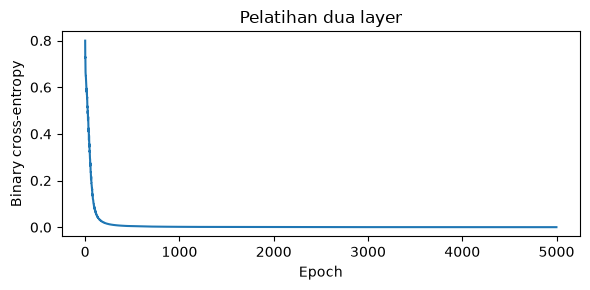

In [5]:
losses = []
learning_rate = .5
for epoch in range(5000):
    _, _, probabilities = forward(W1, b1, W2, b2)
    losses.append(bce(probabilities))
    gW1, gb1, gW2, gb2 = gradients(W1, b1, W2, b2)
    W1 -= learning_rate * gW1
    b1 -= learning_rate * gb1
    W2 -= learning_rate * gW2
    b2 -= learning_rate * gb2

_, hidden, probabilities = forward(W1, b1, W2, b2)
print('BCE awal/akhir:', round(losses[0], 4), round(losses[-1], 6))
print('Probabilitas training:', probabilities.ravel().round(3))
print('Target:', y.ravel().astype(int))
print('Akurasi training:', np.mean((probabilities >= .5) == y))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(losses); ax.set(xlabel='Epoch', ylabel='Binary cross-entropy', title='Pelatihan dua layer')
plt.tight_layout(); plt.show()
assert np.array_equal((probabilities >= .5).astype(int), y.astype(int))

## 5. Apa yang telah dan belum dibuktikan?

Jaringan dua layer menemukan pemetaan nonlinier untuk keempat pola latihan. Hasil ini mendemonstrasikan forward pass, chain rule, dan pembaruan bobot, **bukan** estimasi akurasi di dunia nyata. Dataset hanya empat pola tanpa split independen; output tidak layak dipakai sebagai aturan menyeberang jalan. Penilaian model nyata memerlukan data representatif yang lebih besar, pemisahan train/validation/test, pemeriksaan bias, serta batas penggunaan yang aman.

### Ringkasan

- Hidden layer menciptakan representasi intermediate; nonlinieritas membuatnya lebih ekspresif dari satu transformasi linear.
- Backpropagation mengatribusikan error output ke setiap bobot melalui chain rule.
- Gradien bisa diperiksa dengan beda hingga sebelum training panjang. Hasil juga peka terhadap inisialisasi: ReLU yang tidak aktif dapat membuat gradien tersekat.
- Loss training menurun dan akurasi training sempurna tidak sama dengan generalisasi.